In [34]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set project paths
homework_folder = Path.cwd()
project_folder = homework_folder.parent.parent

sys.path.insert(0, str(project_folder))
sys.path.insert(0, str(homework_folder))

# Import classes
from enums import *
from market_data import MarketData
from contract import EuropeanContract
from model import BSVolModel
from pricer import EuropeanAnalyticPricer, Params

# Initialize market data
MarketData.initialize()

print("Market data initialized successfully^-^!")


Market data initialized successfully^-^!


In [35]:

# Create a European Call option
stock = Stock.TEST_COMPANY

contract = EuropeanContract(
    underlying=stock,
    derivative_type=PutCallFwd.CALL,
    long_short=LongShort.LONG,
    strike=100.0,
    expiry=1.0
)

# Create the Black-Scholes model
model = BSVolModel(stock)

# Create the pricer
pricer = EuropeanAnalyticPricer(contract, model, Params())

print("Spot:", model.spot)
print("Volatility:", model.get_vol(100.0, 1.0))
print("Option price:", pricer.calc_fair_value())


Spot: 100.0
Volatility: 0.3
Option price: 14.231254785985819


In [36]:

# Calculate analytical Greeks
delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

# Calculate numerical Greeks using Central Difference
pricer.finite_difference_method = FiniteDifferenceMethod.CENTRAL
pricer.bump_size_type = BumpSizeType.RELATIVE

delta_numerical = pricer.calc_delta(GreekMethod.BUMP)
gamma_numerical = pricer.calc_gamma(GreekMethod.BUMP)

print("Analytical Delta:", delta_analytic)
print("Numerical Delta:", delta_numerical)
print()
print("Analytical Gamma:", gamma_analytic)
print("Numerical Gamma:", gamma_numerical)


Analytical Delta: 0.6242517279060125
Numerical Delta: 0.6242084056517818

Analytical Gamma: 0.012647764437231512
Numerical Gamma: 0.012647255227754783


In [37]:

# Set bump sizes
pricer.relative_bump_size = 0.01
pricer.absolute_bump_size = 0.5

results = []

# Test all numerical methods
for method in FiniteDifferenceMethod:
    for bump_type in BumpSizeType:

        pricer.finite_difference_method = method
        pricer.bump_size_type = bump_type

        delta = pricer.calc_delta(GreekMethod.BUMP)
        gamma = pricer.calc_gamma(GreekMethod.BUMP)

        results.append({
            "Method": method.value,
            "Bump type": bump_type.value,
            "Delta": delta,
            "Gamma": gamma,
            "Delta error": abs(delta - delta_analytic),
            "Gamma error": abs(gamma - gamma_analytic)
        })

df = pd.DataFrame(results)
display(df)


,Method,Bump type,Delta,Gamma,Delta error,Gamma error
0,FORWARD,ABSOLUTE,0.627403,0.012517,0.003151,1.308519e-04
1,FORWARD,RELATIVE,0.630532,0.012384,0.006280,2.633075e-04
2,BACKWARD,ABSOLUTE,0.621079,0.012777,0.003173,1.290696e-04
3,BACKWARD,RELATIVE,0.617885,0.012904,0.006367,2.561732e-04
4,CENTRAL,ABSOLUTE,0.624241,0.012648,0.000011,1.272815e-07
5,CENTRAL,RELATIVE,0.624208,0.012647,0.000043,5.092095e-07


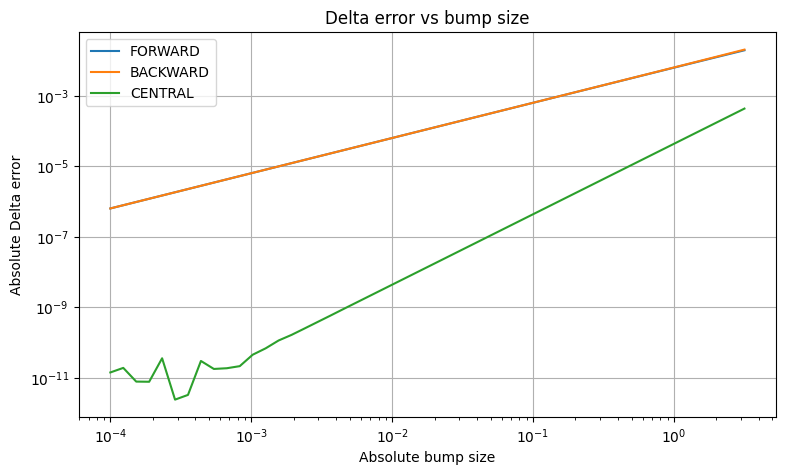

In [38]:


# Different absolute bump sizes
bump_sizes = np.logspace(-4, 0.5, 50)

delta_errors = {}

pricer.bump_size_type = BumpSizeType.ABSOLUTE

for method in FiniteDifferenceMethod:
    errors = []

    pricer.finite_difference_method = method

    for h in bump_sizes:
        pricer.absolute_bump_size = h

        delta = pricer.calc_delta(GreekMethod.BUMP)
        error = abs(delta - delta_analytic)

        errors.append(error)

    delta_errors[method.value] = errors

# Plot absolute errors
plt.figure(figsize=(9, 5))

for method, errors in delta_errors.items():
    plt.loglog(bump_sizes, errors, label=method)

plt.xlabel("Absolute bump size")
plt.ylabel("Absolute Delta error")
plt.title("Delta error vs bump size")
plt.legend()
plt.grid(True)
plt.show()


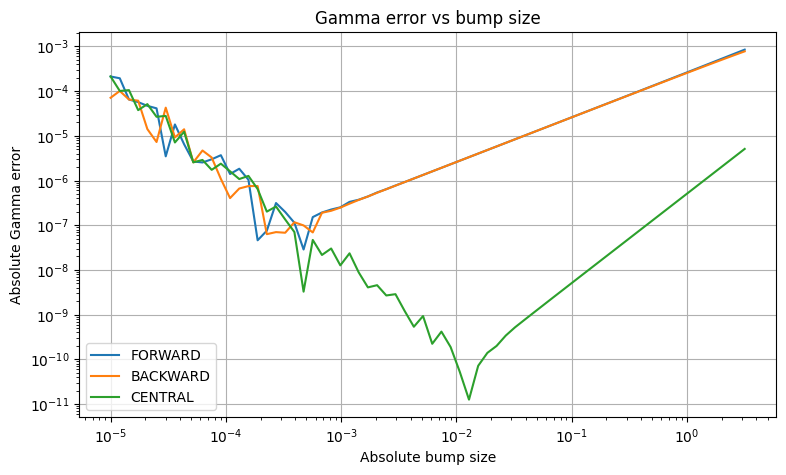

In [39]:

# Different absolute bump sizes
bump_sizes = np.logspace(-5, 0.5, 70)

gamma_errors = {}

pricer.bump_size_type = BumpSizeType.ABSOLUTE

for method in FiniteDifferenceMethod:
    errors = []

    pricer.finite_difference_method = method

    for h in bump_sizes:
        pricer.absolute_bump_size = h

        gamma = pricer.calc_gamma(GreekMethod.BUMP)
        error = abs(gamma - gamma_analytic)

        errors.append(error)

    gamma_errors[method.value] = errors

# Plot absolute Gamma errors
plt.figure(figsize=(9, 5))

for method, errors in gamma_errors.items():
    plt.loglog(bump_sizes, errors, label=method)

plt.xlabel("Absolute bump size")
plt.ylabel("Absolute Gamma error")
plt.title("Gamma error vs bump size")
plt.legend()
plt.grid(True)
plt.show()


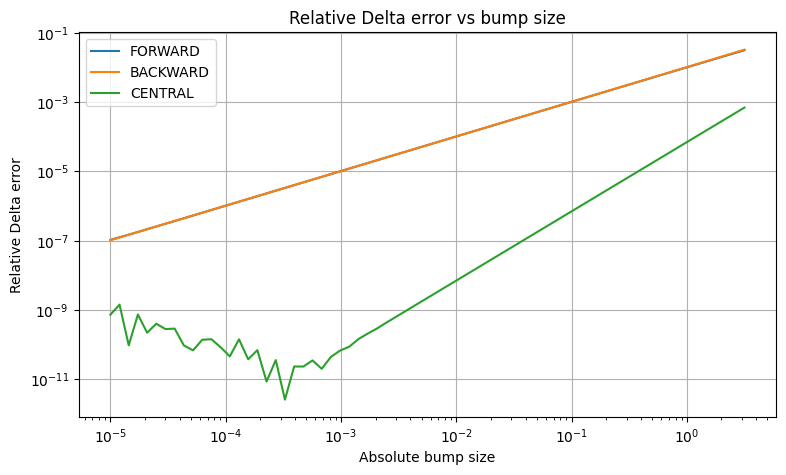

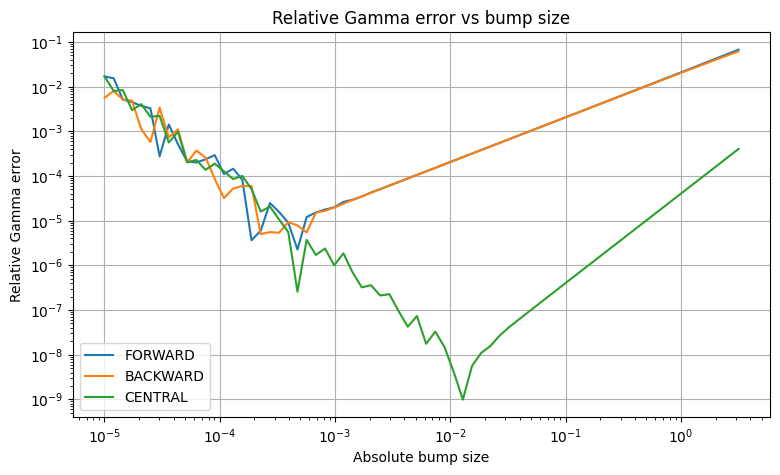

In [40]:


# Different absolute bump sizes
bump_sizes = np.logspace(-5, 0.5, 70)

delta_relative_errors = {}
gamma_relative_errors = {}

pricer.bump_size_type = BumpSizeType.ABSOLUTE

# Calculate relative errors for all methods
for method in FiniteDifferenceMethod:
    delta_errors = []
    gamma_errors = []

    pricer.finite_difference_method = method

    for h in bump_sizes:
        pricer.absolute_bump_size = h

        delta = pricer.calc_delta(GreekMethod.BUMP)
        gamma = pricer.calc_gamma(GreekMethod.BUMP)

        delta_error = abs(delta - delta_analytic) / abs(delta_analytic)
        gamma_error = abs(gamma - gamma_analytic) / abs(gamma_analytic)

        delta_errors.append(delta_error)
        gamma_errors.append(gamma_error)

    delta_relative_errors[method.value] = delta_errors
    gamma_relative_errors[method.value] = gamma_errors

# Plot relative Delta errors
plt.figure(figsize=(9, 5))

for method, errors in delta_relative_errors.items():
    plt.loglog(bump_sizes, errors, label=method)

plt.xlabel("Absolute bump size")
plt.ylabel("Relative Delta error")
plt.title("Relative Delta error vs bump size")
plt.legend()
plt.grid(True)
plt.show()

# Plot relative Gamma errors
plt.figure(figsize=(9, 5))

for method, errors in gamma_relative_errors.items():
    plt.loglog(bump_sizes, errors, label=method)

plt.xlabel("Absolute bump size")
plt.ylabel("Relative Gamma error")
plt.title("Relative Gamma error vs bump size")
plt.legend()
plt.grid(True)
plt.show()


In [41]:

# Find the best bump sizes for Delta and Gamma

optimal_results = []

spot = pricer.model.spot

for method in FiniteDifferenceMethod:
    name = method.value

    # Find minimum errors
    delta_errors = np.array(delta_relative_errors[name])
    gamma_errors = np.array(gamma_relative_errors[name])

    delta_index = np.argmin(delta_errors)
    gamma_index = np.argmin(gamma_errors)

    optimal_results.append({
        "Method": name,
        "Greek": "Delta",
        "Optimal absolute bump": bump_sizes[delta_index],
        "Optimal relative bump": bump_sizes[delta_index] / spot,
        "Minimum relative error": delta_errors[delta_index]
    })

    optimal_results.append({
        "Method": name,
        "Greek": "Gamma",
        "Optimal absolute bump": bump_sizes[gamma_index],
        "Optimal relative bump": bump_sizes[gamma_index] / spot,
        "Minimum relative error": gamma_errors[gamma_index]
    })

optimal_df = pd.DataFrame(optimal_results)

display(optimal_df)


,Method,Greek,Optimal absolute bump,Optimal relative bump,Minimum relative error
0,FORWARD,Delta,0.000010,1.000000e-07,1.037274e-07
1,FORWARD,Gamma,0.000472,4.719685e-06,2.264063e-06
2,BACKWARD,Delta,0.000010,1.000000e-07,1.022924e-07
3,BACKWARD,Gamma,0.000227,2.265022e-06,4.988480e-06
4,CENTRAL,Delta,0.000327,3.269586e-06,2.533453e-12
5,CENTRAL,Gamma,0.012844,1.284386e-04,9.890172e-10


In [42]:

# Compare Greeks for different European options

options = [
    (PutCallFwd.CALL, 100.0, 1.0),
    (PutCallFwd.PUT, 100.0, 1.0),
    (PutCallFwd.CALL, 110.0, 0.5),
    (PutCallFwd.PUT, 90.0, 2.0)
]

results = []

for option_type, strike, expiry in options:

    contract = EuropeanContract(
        underlying=Stock.TEST_COMPANY,
        derivative_type=option_type,
        long_short=LongShort.LONG,
        strike=strike,
        expiry=expiry
    )

    model = BSVolModel(Stock.TEST_COMPANY)
    pricer = EuropeanAnalyticPricer(contract, model, Params())

    delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
    gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

    pricer.bump_size_type = BumpSizeType.ABSOLUTE
    pricer.absolute_bump_size = 0.01

    for method in FiniteDifferenceMethod:

        pricer.finite_difference_method = method

        delta = pricer.calc_delta(GreekMethod.BUMP)
        gamma = pricer.calc_gamma(GreekMethod.BUMP)

        results.append({
            "Option": option_type.value,
            "Strike": strike,
            "Expiry": expiry,
            "Method": method.value,
            "Delta error": abs(delta - delta_analytic),
            "Gamma error": abs(gamma - gamma_analytic)
        })

comparison_df = pd.DataFrame(results)

display(comparison_df)


,Option,Strike,Expiry,Method,Delta error,Gamma error
0,CALL,100.0,1.0,FORWARD,6.323449e-05,2.600588e-06
1,CALL,100.0,1.0,BACKWARD,6.324316e-05,2.599519e-06
2,CALL,100.0,1.0,CENTRAL,4.332291e-09,2.117005e-10
3,PUT,100.0,1.0,FORWARD,6.323449e-05,2.600090e-06
4,PUT,100.0,1.0,BACKWARD,6.324316e-05,2.599377e-06
5,PUT,100.0,1.0,CENTRAL,4.333514e-09,7.251658e-11
6,CALL,110.0,0.5,FORWARD,9.167365e-05,1.119889e-07
7,CALL,110.0,0.5,BACKWARD,9.167327e-05,1.168058e-07
8,CALL,110.0,0.5,CENTRAL,1.914908e-10,3.478938e-10
9,PUT,90.0,2.0,FORWARD,3.689472e-05,1.948708e-06


In [43]:

# Compare absolute and relative bump sizes

stocks = [
    Stock.TEST_COMPANY,
    Stock.BLUECHIP_BANK,
    Stock.TIPTOP_SOLUTIONS
]

results = []

for stock in stocks:

    model = BSVolModel(stock)
    spot = float(model.spot)

    # Create an ATM European Call
    contract = EuropeanContract(
        underlying=stock,
        derivative_type=PutCallFwd.CALL,
        long_short=LongShort.LONG,
        strike=spot,
        expiry=1.0
    )

    pricer = EuropeanAnalyticPricer(contract, model, Params())

    delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
    gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

    pricer.absolute_bump_size = 0.01
    pricer.relative_bump_size = 0.0001

    for bump_type in BumpSizeType:
        pricer.bump_size_type = bump_type

        for method in FiniteDifferenceMethod:
            pricer.finite_difference_method = method

            delta = pricer.calc_delta(GreekMethod.BUMP)
            gamma = pricer.calc_gamma(GreekMethod.BUMP)

            results.append({
                "Stock": stock.value,
                "Spot": spot,
                "Bump type": bump_type.value,
                "Method": method.value,
                "Actual bump": pricer._get_bump_size(),
                "Delta error": abs(delta - delta_analytic),
                "Gamma error": abs(gamma - gamma_analytic)
            })

bump_comparison_df = pd.DataFrame(results)

display(bump_comparison_df)


,Stock,Spot,Bump type,Method,Actual bump,Delta error,Gamma error
0,TEST_COMPANY,100.00,ABSOLUTE,FORWARD,0.010000,6.323449e-05,2.600588e-06
1,TEST_COMPANY,100.00,ABSOLUTE,BACKWARD,0.010000,6.324316e-05,2.599519e-06
2,TEST_COMPANY,100.00,ABSOLUTE,CENTRAL,0.010000,4.332291e-09,2.117005e-10
3,TEST_COMPANY,100.00,RELATIVE,FORWARD,0.010000,6.323449e-05,2.600588e-06
4,TEST_COMPANY,100.00,RELATIVE,BACKWARD,0.010000,6.324316e-05,2.599519e-06
5,TEST_COMPANY,100.00,RELATIVE,CENTRAL,0.010000,4.332291e-09,2.117005e-10
6,BLUECHIP_BANK,130.17,ABSOLUTE,FORWARD,0.010000,3.820707e-05,1.083042e-06
7,BLUECHIP_BANK,130.17,ABSOLUTE,BACKWARD,0.010000,3.821068e-05,1.082551e-06
8,BLUECHIP_BANK,130.17,ABSOLUTE,CENTRAL,0.010000,1.805718e-09,1.808893e-10
9,BLUECHIP_BANK,130.17,RELATIVE,FORWARD,0.013017,4.973343e-05,1.409664e-06
